In [64]:
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import kaggle
from kaggle.api.kaggle_api_extended import KaggleApi
from langgraph.prebuilt import ToolNode
import os
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START,END

In [65]:
load_dotenv()

os.environ['LANGSMITH_API_KEY'] = os.getenv('LANGSMITH_API_KEY')
os.environ['LANGSMITH_TRACING']="true"

memory = MemorySaver()

In [66]:
llm = init_chat_model(model="groq:llama-3.3-70b-versatile")
llm

ChatGroq(profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x711ba9375340>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x711bab47a690>, model_name='llama-3.3-70b-versatile', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [67]:
class State(TypedDict):
    messages:Annotated[list,add_messages] 

In [68]:
import os
import glob
api = KaggleApi()
api.authenticate

def search_download_tool(keyword:str) -> str:
    ''' Args: 
    keyword: Dataset keyword for searching in the kaggle 

        Returns:
    path of the downloaded dataset
    '''
    results = api.dataset_list(search=keyword)
    if not results:
        print("No dataset found.")
    else:
        top_dataset = results[0]
        dataset_slug = top_dataset.ref
    api.dataset_download_files(dataset_slug, path="./data", unzip=True)

    return f"Dataset downloaded to ./data"

In [69]:
from ydata_profiling import ProfileReport
import pandas as pd

def eda_report_tool(name:str) -> str:
    ''' Args:
    name: name for the dataset file

    
    Returns A base EDA on the topic in the html file.
    '''
    #get the most recently modified(downloaded) csv file
    csv_files = glob.glob("./data/*.csv")
    csv_path = max(csv_files,key=os.path.getmtime) if csv_files else "./data/"
    df = pd.read_csv(csv_path)
    profile = ProfileReport(df, title=name, explorative=True)
    profile.to_file(f"{name}.html")
    return f"EDA file created."

In [70]:
def should_continue(state:State):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"
    return END
        

In [71]:
tool_node = ToolNode([search_download_tool,eda_report_tool])
llm_with_tools = llm.bind_tools([search_download_tool,eda_report_tool])

In [72]:
from langchain_core.messages import SystemMessage

def agent_node(state:State):
    system_msg = SystemMessage(content="""You are a helpful assistant that can search and download Kaggle datasets and perform EDA.
    
Rules:
- First search and download the dataset using search_download_tool
- Then create EDA report using eda_report_tool
- After EDA report is created, DO NOT call any more tools. Simply respond that the task is complete.
- Never repeat a tool call that has already succeeded.""")
    
    messages = [system_msg] + state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": response}

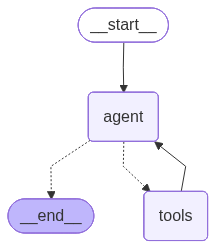

In [73]:

builder = StateGraph(State)
builder.add_node("agent",agent_node)
builder.add_node("tools",tool_node)
builder.add_edge(START,"agent")
builder.add_conditional_edges(
    "agent",
    should_continue,
    ["tools",END]
)
builder.add_edge("tools","agent")
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [74]:
config={"configurable":{"thread_id":"2"}}
out = graph.invoke(
    {"messages":"do eda on social media dataset"},
    config=config
)
out

Summarize dataset:  18%|█▊        | 7/38 [00:00<00:01, 18.22it/s, Describe variable: famsup]    

Dataset URL: https://www.kaggle.com/datasets/kashishparmar02/social-media-sentiments-analysis-dataset


Export report to file: 100%|██████████| 1/1 [00:00<00:00, 291.11it/s]



{'messages': [HumanMessage(content='do eda on social media dataset', additional_kwargs={}, response_metadata={}, id='713e9636-43b3-4dc0-af43-5c6d8698aea1'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '1yep1tnbq', 'function': {'arguments': '{"keyword":"social media dataset"}', 'name': 'search_download_tool'}, 'type': 'function'}, {'id': 'b4bjxm134', 'function': {'arguments': '{"name":"social media dataset.csv"}', 'name': 'eda_report_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 344, 'total_tokens': 379, 'completion_time': 0.089822408, 'completion_tokens_details': None, 'prompt_time': 0.033573117, 'prompt_tokens_details': None, 'queue_time': 0.161782272, 'total_time': 0.123395525}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_45180df409', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019af9dd-f653-7ef2-97af-dd12bb